LABERINTO
Inicio: (10, 11)
Meta: (14, 8)
Obstáculos:
  (0, 11)
  (3, 2)
  (4, 3)
  (10, 1)
  (11, 1)

Entrenando Q-Learning...
Q-Learning terminado.

Entrenando Policy Gradient...
Policy Gradient terminado.


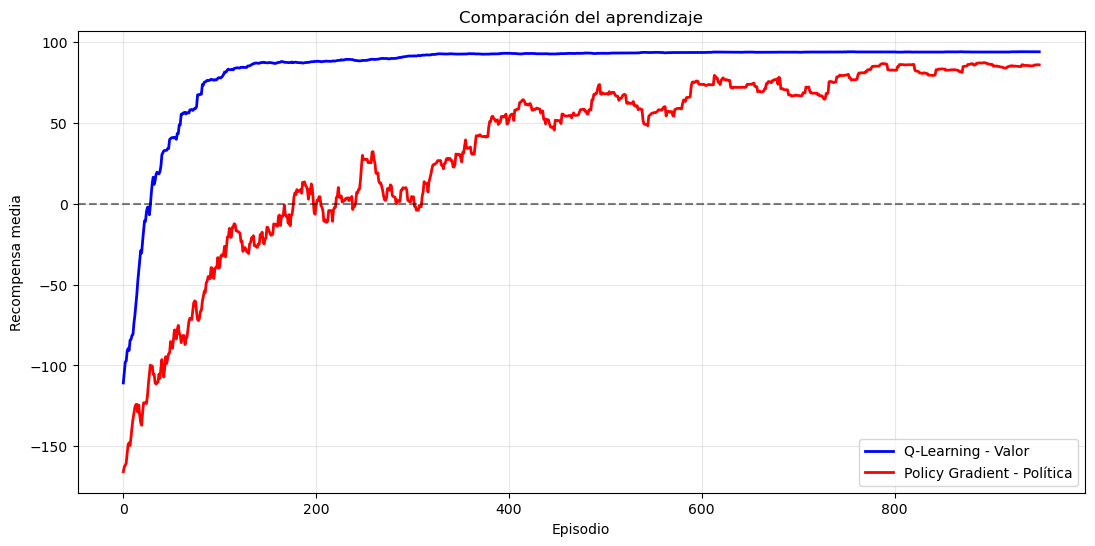

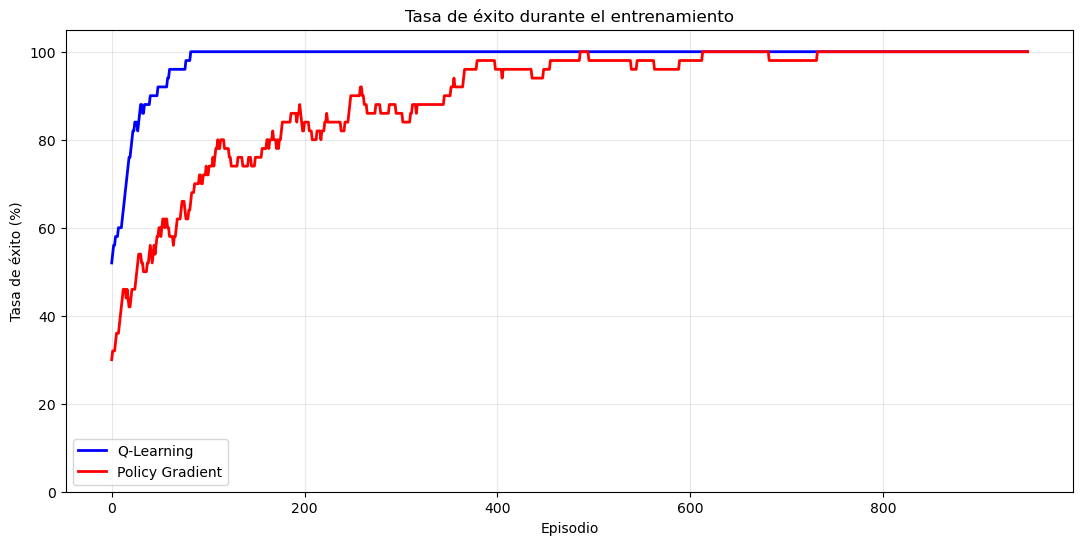

In [18]:
%matplotlib inline

import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from IPython.display import HTML, display
from matplotlib.colors import ListedColormap


# ============================================================
# CONFIGURACIÓN
# ============================================================

GRID_SIZE = 15
NUM_OBSTACLES = 5

ACTIONS = [
    (-1, 0),   # Arriba
    (1, 0),    # Abajo
    (0, -1),   # Izquierda
    (0, 1)     # Derecha
]

N_ACTIONS = 4

EPISODES = 1000
MAX_STEPS = 200

GAMMA = 0.95

# Q-Learning
ALPHA = 0.15

# Policy Gradient
POLICY_LR = 0.03

# Cada cuántos episodios guardar una "fotografía"
SNAPSHOT_EVERY = 50

# Semilla para que el experimento sea reproducible
SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# ============================================================
# ENTORNO
# ============================================================

class MazeEnvironment:

    def __init__(self):

        self.obstacles = set()

        while len(self.obstacles) < NUM_OBSTACLES:

            obs = (
                random.randint(0, GRID_SIZE - 1),
                random.randint(0, GRID_SIZE - 1)
            )

            self.obstacles.add(obs)

        # Crear inicio y meta
        while True:

            self.start = (
                random.randint(0, GRID_SIZE - 1),
                random.randint(0, GRID_SIZE - 1)
            )

            self.end = (
                random.randint(0, GRID_SIZE - 1),
                random.randint(0, GRID_SIZE - 1)
            )

            if (
                self.start != self.end
                and self.start not in self.obstacles
                and self.end not in self.obstacles
            ):
                break

        self.agent_pos = self.start

    def reset(self):

        self.agent_pos = self.start

        return self.agent_pos

    def step(self, action):

        dr, dc = ACTIONS[action]

        r, c = self.agent_pos

        next_pos = (
            r + dr,
            c + dc
        )

        # Fuera del tablero
        if not (
            0 <= next_pos[0] < GRID_SIZE
            and
            0 <= next_pos[1] < GRID_SIZE
        ):

            return self.agent_pos, -5, False

        # Obstáculo
        if next_pos in self.obstacles:

            return self.agent_pos, -5, False

        # Movimiento válido
        self.agent_pos = next_pos

        # Meta
        if self.agent_pos == self.end:

            return self.agent_pos, 100, True

        # Paso normal
        return self.agent_pos, -1, False


# ============================================================
# UTILIDADES
# ============================================================

def softmax(x):

    x = x - np.max(x)

    exp_x = np.exp(x)

    return exp_x / np.sum(exp_x)


def get_state_index(state):

    return state[0] * GRID_SIZE + state[1]


# ============================================================
# Q-LEARNING
# MÉTODO BASADO EN VALOR
# ============================================================

def train_q_learning(env):

    Q = np.zeros(
        (
            GRID_SIZE,
            GRID_SIZE,
            N_ACTIONS
        )
    )

    epsilon = 1.0
    epsilon_min = 0.02
    epsilon_decay = 0.995

    rewards = []
    successes = []

    snapshots = []
    snapshot_episodes = []

    for episode in range(EPISODES):

        state = env.reset()

        total_reward = 0

        done = False

        for step in range(MAX_STEPS):

            r, c = state

            # ------------------------------------------------
            # Epsilon-Greedy
            # ------------------------------------------------

            if random.random() < epsilon:

                action = random.randint(
                    0,
                    N_ACTIONS - 1
                )

            else:

                values = Q[r, c]

                best_actions = np.flatnonzero(
                    values == np.max(values)
                )

                action = random.choice(
                    best_actions
                )

            # ------------------------------------------------
            # Ejecutar
            # ------------------------------------------------

            next_state, reward, done = env.step(action)

            nr, nc = next_state

            # ------------------------------------------------
            # Q-Learning
            # ------------------------------------------------

            if done:

                target = reward

            else:

                target = (
                    reward
                    +
                    GAMMA * np.max(Q[nr, nc])
                )

            Q[r, c, action] += ALPHA * (
                target
                -
                Q[r, c, action]
            )

            state = next_state

            total_reward += reward

            if done:

                break

        rewards.append(total_reward)

        successes.append(
            1 if done else 0
        )

        # ----------------------------------------------------
        # Guardar snapshot
        # ----------------------------------------------------

        if (
            episode % SNAPSHOT_EVERY == 0
            or episode == EPISODES - 1
        ):

            value_map = np.max(
                Q,
                axis=2
            )

            snapshots.append(
                value_map.copy()
            )

            snapshot_episodes.append(
                episode + 1
            )

        # ----------------------------------------------------
        # Reducir exploración
        # ----------------------------------------------------

        epsilon = max(
            epsilon_min,
            epsilon * epsilon_decay
        )

    return (
        Q,
        rewards,
        successes,
        snapshots,
        snapshot_episodes
    )


# ============================================================
# POLICY GRADIENT TABULAR
# MÉTODO BASADO EN POLÍTICA
# ============================================================

def train_policy_gradient(env):

    # --------------------------------------------------------
    # theta representa la política.
    #
    # theta[s,a] = preferencia por acción a en estado s
    # --------------------------------------------------------

    theta = np.zeros(
        (
            GRID_SIZE * GRID_SIZE,
            N_ACTIONS
        )
    )

    rewards_history = []
    successes = []

    snapshots = []
    snapshot_episodes = []

    for episode in range(EPISODES):

        state = env.reset()

        states = []
        actions = []
        rewards = []

        done = False

        # ----------------------------------------------------
        # Generar episodio
        # ----------------------------------------------------

        for step in range(MAX_STEPS):

            s = get_state_index(state)

            # Política
            probabilities = softmax(
                theta[s]
            )

            action = np.random.choice(
                N_ACTIONS,
                p=probabilities
            )

            next_state, reward, done = env.step(
                action
            )

            states.append(s)
            actions.append(action)
            rewards.append(reward)

            state = next_state

            if done:

                break

        # ----------------------------------------------------
        # Calcular retornos
        # ----------------------------------------------------

        returns = np.zeros(
            len(rewards)
        )

        G = 0

        for t in reversed(
            range(len(rewards))
        ):

            G = (
                rewards[t]
                +
                GAMMA * G
            )

            returns[t] = G

        # ----------------------------------------------------
        # Normalizar retornos
        # ----------------------------------------------------

        if len(returns) > 1:

            returns = (
                returns - np.mean(returns)
            ) / (
                np.std(returns) + 1e-8
            )

        # ----------------------------------------------------
        # REINFORCE
        # ----------------------------------------------------

        for t in range(len(states)):

            s = states[t]

            a = actions[t]

            G = returns[t]

            probabilities = softmax(
                theta[s]
            )

            # Gradiente de log pi(a|s)
            gradient = -probabilities

            gradient[a] += 1

            theta[s] += (
                POLICY_LR
                *
                G
                *
                gradient
            )

        total_reward = sum(rewards)

        rewards_history.append(
            total_reward
        )

        successes.append(
            1 if done else 0
        )

        # ----------------------------------------------------
        # Snapshot
        # ----------------------------------------------------

        if (
            episode % SNAPSHOT_EVERY == 0
            or episode == EPISODES - 1
        ):

            # Probabilidad de la mejor acción
            policy_map = np.zeros(
                (
                    GRID_SIZE,
                    GRID_SIZE
                )
            )

            for s in range(
                GRID_SIZE * GRID_SIZE
            ):

                probabilities = softmax(
                    theta[s]
                )

                r = s // GRID_SIZE
                c = s % GRID_SIZE

                policy_map[r, c] = np.max(
                    probabilities
                )

            snapshots.append(
                policy_map.copy()
            )

            snapshot_episodes.append(
                episode + 1
            )

    return (
        theta,
        rewards_history,
        successes,
        snapshots,
        snapshot_episodes
    )


# ============================================================
# CREAR MISMO LABERINTO PARA LOS DOS MÉTODOS
# ============================================================

env = MazeEnvironment()

print("========================================")
print("LABERINTO")
print("========================================")

print("Inicio:", env.start)
print("Meta:", env.end)

print("Obstáculos:")

for obstacle in sorted(env.obstacles):

    print(" ", obstacle)


# ============================================================
# ENTRENAR Q-LEARNING
# ============================================================

print("\nEntrenando Q-Learning...")

Q, q_rewards, q_success, q_snapshots, q_episodes = (
    train_q_learning(env)
)

print("Q-Learning terminado.")


# ============================================================
# ENTRENAR POLICY GRADIENT
# ============================================================

print("\nEntrenando Policy Gradient...")

theta, p_rewards, p_success, p_snapshots, p_episodes = (
    train_policy_gradient(env)
)

print("Policy Gradient terminado.")


# ============================================================
# COMPARACIÓN DE RECOMPENSA
# ============================================================

def moving_average(data, window=50):

    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


plt.figure(figsize=(13, 6))

plt.plot(
    moving_average(q_rewards),
    label="Q-Learning - Valor",
    color="blue",
    linewidth=2
)

plt.plot(
    moving_average(p_rewards),
    label="Policy Gradient - Política",
    color="red",
    linewidth=2
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    alpha=0.5
)

plt.xlabel("Episodio")

plt.ylabel("Recompensa media")

plt.title(
    "Comparación del aprendizaje"
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()


# ============================================================
# TASA DE ÉXITO
# ============================================================

q_success_rate = moving_average(
    q_success,
    50
)

p_success_rate = moving_average(
    p_success,
    50
)

plt.figure(figsize=(13, 6))

plt.plot(
    q_success_rate * 100,
    color="blue",
    linewidth=2,
    label="Q-Learning"
)

plt.plot(
    p_success_rate * 100,
    color="red",
    linewidth=2,
    label="Policy Gradient"
)

plt.xlabel("Episodio")

plt.ylabel("Tasa de éxito (%)")

plt.title(
    "Tasa de éxito durante el entrenamiento"
)

plt.ylim(0, 105)

plt.legend()

plt.grid(alpha=0.3)

plt.show()


# ============================================================
# ANIMACIÓN DE LOS MAPAS DE APRENDIZAJE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 6)
)

ax_value = axes[0]
ax_policy = axes[1]


# ------------------------------------------------------------
# Q-LEARNING
# ------------------------------------------------------------

im_q = ax_value.imshow(
    q_snapshots[0],
    cmap="viridis",
    vmin=np.min(q_snapshots[0]),
    vmax=max(
        1,
        np.max(q_snapshots[-1])
    )
)

ax_value.set_title(
    "Q-Learning\nBasado en VALOR"
)


# ------------------------------------------------------------
# POLICY GRADIENT
# ------------------------------------------------------------

im_p = ax_policy.imshow(
    p_snapshots[0],
    cmap="plasma",
    vmin=0,
    vmax=1
)

ax_policy.set_title(
    "Policy Gradient\nBasado en POLÍTICA"
)


# ------------------------------------------------------------
# Dibujar elementos del laberinto
# ------------------------------------------------------------

for ax in axes:

    for obstacle in env.obstacles:

        ax.scatter(
            obstacle[1],
            obstacle[0],
            color="black",
            s=150,
            marker="s"
        )

    ax.scatter(
        env.start[1],
        env.start[0],
        color="dodgerblue",
        s=150,
        marker="o"
    )

    ax.scatter(
        env.end[1],
        env.end[0],
        color="limegreen",
        s=180,
        marker="*"
    )

    ax.set_xticks(
        np.arange(
            -0.5,
            GRID_SIZE,
            1
        ),
        minor=True
    )

    ax.set_yticks(
        np.arange(
            -0.5,
            GRID_SIZE,
            1
        ),
        minor=True
    )

    ax.grid(
        which="minor",
        color="gray",
        linewidth=0.5
    )

    ax.set_xticks([])
    ax.set_yticks([])


# ============================================================
# ACTUALIZACIÓN
# ============================================================

n_frames = min(
    len(q_snapshots),
    len(p_snapshots)
)


def update_learning(frame):

    im_q.set_data(
        q_snapshots[frame]
    )

    im_p.set_data(
        p_snapshots[frame]
    )

    episode = q_episodes[frame]

    ax_value.set_title(
        "Q-Learning\n"
        "Basado en VALOR\n"
        f"Episodio {episode}"
    )

    ax_policy.set_title(
        "Policy Gradient\n"
        "Basado en POLÍTICA\n"
        f"Episodio {episode}"
    )

    return [
        im_q,
        im_p
    ]


ani_learning = animation.FuncAnimation(
    fig,
    update_learning,
    frames=n_frames,
    interval=700,
    blit=False,
    repeat=True
)

plt.close(fig)

display(
    HTML(
        ani_learning.to_jshtml()
    )
)

LABERINTO
Inicio: (10, 11)
Meta  : (14, 8)
Obstáculos:
  (0, 11)
  (3, 2)
  (4, 3)
  (10, 1)
  (11, 1)

Entrenando Monte Carlo...
Entrenando TD(0)...
Entrenando Q-Learning...

VALORES APRENDIDOS
Monte Carlo : -19.970131786899376 a 0.0
TD(0)       : -4.822136808084403 a 10.062791516337704
Q-Learning  : -1.8885524283098352 a 99.99999999999994


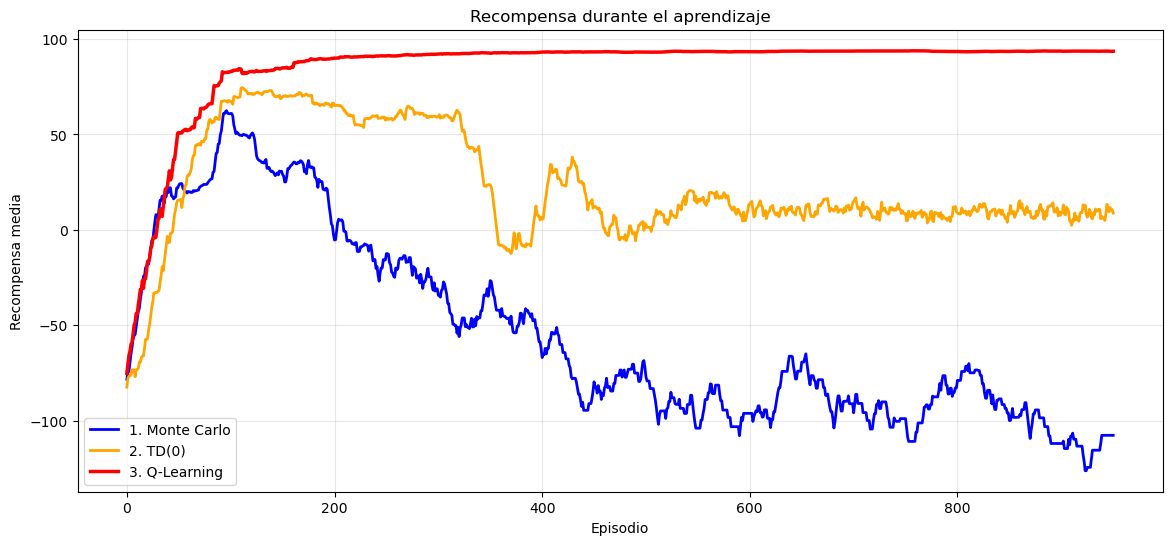

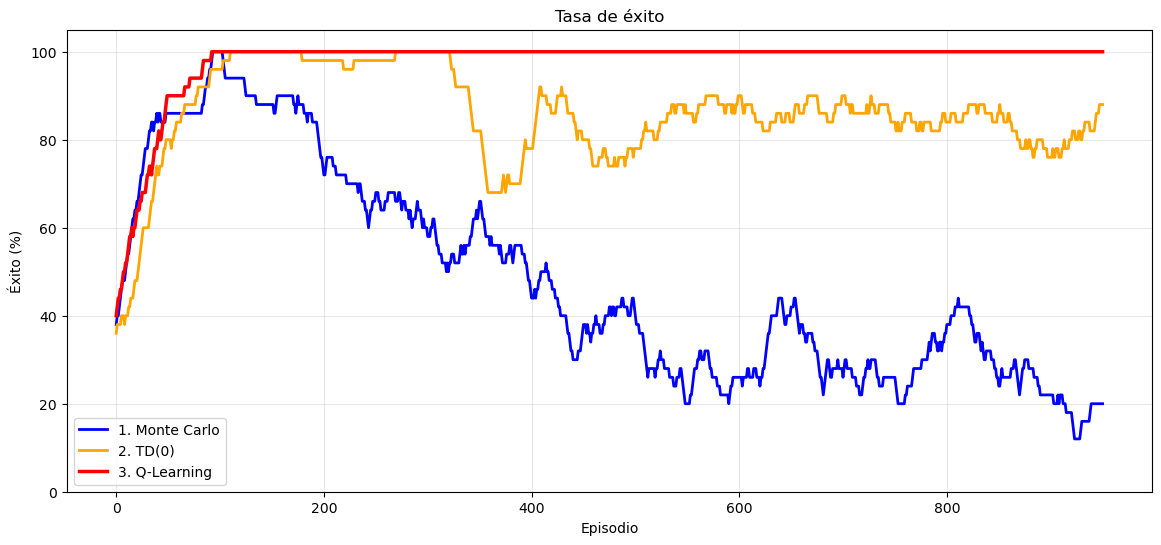

In [22]:
%matplotlib inline

import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from IPython.display import HTML, display


# ============================================================
# CONFIGURACIÓN
# ============================================================

GRID_SIZE = 15
NUM_OBSTACLES = 5

EPISODES = 1000
MAX_STEPS = 150

ALPHA = 0.10
GAMMA = 0.95

EPSILON_START = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.995

# Guardar mapa cada N episodios
SNAPSHOT_EVERY = 10

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# ============================================================
# ACCIONES
# ============================================================

ACTIONS = [
    (-1, 0),   # arriba
    (1, 0),    # abajo
    (0, -1),   # izquierda
    (0, 1)     # derecha
]

N_ACTIONS = len(ACTIONS)


# ============================================================
# RECOMPENSAS
# ============================================================

REWARD_GOAL = 100
REWARD_STEP = -1
REWARD_COLLISION = -5


# ============================================================
# ENTORNO
# ============================================================

class MazeEnvironment:

    def __init__(self):

        # ----------------------------------------------------
        # Obstáculos
        # ----------------------------------------------------

        self.obstacles = set()

        while len(self.obstacles) < NUM_OBSTACLES:

            obstacle = (
                random.randint(0, GRID_SIZE - 1),
                random.randint(0, GRID_SIZE - 1)
            )

            self.obstacles.add(obstacle)

        # ----------------------------------------------------
        # Inicio y meta
        # ----------------------------------------------------

        while True:

            self.start = (
                random.randint(0, GRID_SIZE - 1),
                random.randint(0, GRID_SIZE - 1)
            )

            self.goal = (
                random.randint(0, GRID_SIZE - 1),
                random.randint(0, GRID_SIZE - 1)
            )

            if (
                self.start != self.goal
                and self.start not in self.obstacles
                and self.goal not in self.obstacles
            ):
                break

        self.agent_pos = self.start

    # --------------------------------------------------------

    def reset(self):

        self.agent_pos = self.start

        return self.agent_pos

    # --------------------------------------------------------

    def step(self, action):

        r, c = self.agent_pos

        dr, dc = ACTIONS[action]

        nr = r + dr
        nc = c + dc

        next_pos = (nr, nc)

        # ----------------------------------------------------
        # Fuera del tablero
        # ----------------------------------------------------

        if not (
            0 <= nr < GRID_SIZE
            and
            0 <= nc < GRID_SIZE
        ):

            return self.agent_pos, REWARD_COLLISION, False

        # ----------------------------------------------------
        # Obstáculo
        # ----------------------------------------------------

        if next_pos in self.obstacles:

            return self.agent_pos, REWARD_COLLISION, False

        # ----------------------------------------------------
        # Movimiento
        # ----------------------------------------------------

        self.agent_pos = next_pos

        # ----------------------------------------------------
        # Meta
        # ----------------------------------------------------

        if self.agent_pos == self.goal:

            return self.agent_pos, REWARD_GOAL, True

        # ----------------------------------------------------
        # Paso normal
        # ----------------------------------------------------

        return self.agent_pos, REWARD_STEP, False


# ============================================================
# ACCIONES VÁLIDAS
# ============================================================

def valid_actions(env, state):

    r, c = state

    valid = []

    for action, (dr, dc) in enumerate(ACTIONS):

        nr = r + dr
        nc = c + dc

        if not (
            0 <= nr < GRID_SIZE
            and
            0 <= nc < GRID_SIZE
        ):
            continue

        if (nr, nc) in env.obstacles:
            continue

        valid.append(action)

    return valid


# ============================================================
# ELECCIÓN EPSILON-GREEDY PARA V
# ============================================================

def choose_action_from_V(
    env,
    V,
    state,
    epsilon
):

    valid = valid_actions(
        env,
        state
    )

    if len(valid) == 0:
        return None

    # --------------------------------------------------------
    # Exploración
    # --------------------------------------------------------

    if random.random() < epsilon:

        return random.choice(valid)

    # --------------------------------------------------------
    # Explotación
    # --------------------------------------------------------

    r, c = state

    values = []

    for action in valid:

        dr, dc = ACTIONS[action]

        nr = r + dr
        nc = c + dc

        values.append(
            V[nr, nc]
        )

    max_value = max(values)

    best_actions = [
        action
        for action, value in zip(
            valid,
            values
        )
        if value == max_value
    ]

    return random.choice(best_actions)


# ============================================================
# MÉTODO 1
#
# RETORNO ACUMULADO / MONTE CARLO
#
# G_t =
# r(t+1) + gamma*r(t+2) + gamma²*r(t+3) + ...
#
# V(s) <- V(s) + alpha [G - V(s)]
#
# ============================================================

def train_monte_carlo(env):

    V = np.zeros(
        (GRID_SIZE, GRID_SIZE),
        dtype=float
    )

    rewards_history = []
    success_history = []

    snapshots = []
    snapshot_episodes = []

    epsilon = EPSILON_START

    for episode in range(EPISODES):

        state = env.reset()

        trajectory = []

        total_reward = 0

        done = False

        # ----------------------------------------------------
        # Generar episodio
        # ----------------------------------------------------

        for step in range(MAX_STEPS):

            action = choose_action_from_V(
                env,
                V,
                state,
                epsilon
            )

            if action is None:
                break

            next_state, reward, done = env.step(
                action
            )

            # Guardamos estado y recompensa
            trajectory.append(
                (state, reward)
            )

            total_reward += reward

            state = next_state

            if done:
                break

        # ----------------------------------------------------
        # RETORNO ACUMULADO
        # ----------------------------------------------------

        G = 0.0

        # Recorremos el episodio hacia atrás
        for state, reward in reversed(trajectory):

            G = reward + GAMMA * G

            r, c = state

            # ------------------------------------------------
            # ACTUALIZACIÓN MONTE CARLO
            # ------------------------------------------------

            V[r, c] += ALPHA * (
                G - V[r, c]
            )

        rewards_history.append(
            total_reward
        )

        success_history.append(
            int(done)
        )

        # ----------------------------------------------------
        # SNAPSHOT
        # ----------------------------------------------------

        if (
            episode % SNAPSHOT_EVERY == 0
            or episode == EPISODES - 1
        ):

            snapshots.append(
                V.copy()
            )

            snapshot_episodes.append(
                episode + 1
            )

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY
        )

    return (
        V,
        rewards_history,
        success_history,
        snapshots,
        snapshot_episodes
    )


# ============================================================
# MÉTODO 2
#
# TD(0)
#
# V(s) <- V(s) +
# alpha[
#     r + gamma V(s') - V(s)
# ]
#
# ============================================================

def train_td(env):

    V = np.zeros(
        (GRID_SIZE, GRID_SIZE),
        dtype=float
    )

    rewards_history = []
    success_history = []

    snapshots = []
    snapshot_episodes = []

    epsilon = EPSILON_START

    for episode in range(EPISODES):

        state = env.reset()

        total_reward = 0

        done = False

        for step in range(MAX_STEPS):

            action = choose_action_from_V(
                env,
                V,
                state,
                epsilon
            )

            if action is None:
                break

            next_state, reward, done = env.step(
                action
            )

            r, c = state

            nr, nc = next_state

            # ------------------------------------------------
            # TARGET TD
            # ------------------------------------------------

            if done:

                target = reward

            else:

                target = (
                    reward
                    +
                    GAMMA * V[nr, nc]
                )

            # ------------------------------------------------
            # ACTUALIZACIÓN
            # ------------------------------------------------

            V[r, c] += ALPHA * (
                target
                -
                V[r, c]
            )

            state = next_state

            total_reward += reward

            if done:
                break

        rewards_history.append(
            total_reward
        )

        success_history.append(
            int(done)
        )

        if (
            episode % SNAPSHOT_EVERY == 0
            or episode == EPISODES - 1
        ):

            snapshots.append(
                V.copy()
            )

            snapshot_episodes.append(
                episode + 1
            )

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY
        )

    return (
        V,
        rewards_history,
        success_history,
        snapshots,
        snapshot_episodes
    )


# ============================================================
# MÉTODO 3
#
# Q-LEARNING
#
# Q(s,a) <- Q(s,a) +
# alpha[
#     r +
#     gamma max Q(s',a')
#     -
#     Q(s,a)
# ]
#
# ============================================================

def train_q_learning(env):

    Q = np.zeros(
        (
            GRID_SIZE,
            GRID_SIZE,
            N_ACTIONS
        ),
        dtype=float
    )

    rewards_history = []
    success_history = []

    snapshots = []
    snapshot_episodes = []

    epsilon = EPSILON_START

    for episode in range(EPISODES):

        state = env.reset()

        total_reward = 0

        done = False

        for step in range(MAX_STEPS):

            valid = valid_actions(
                env,
                state
            )

            if not valid:
                break

            r, c = state

            # ------------------------------------------------
            # EPSILON GREEDY
            # ------------------------------------------------

            if random.random() < epsilon:

                action = random.choice(valid)

            else:

                q_values = [
                    Q[r, c, a]
                    for a in valid
                ]

                max_q = max(q_values)

                best_actions = [
                    a
                    for a, q in zip(
                        valid,
                        q_values
                    )
                    if q == max_q
                ]

                action = random.choice(
                    best_actions
                )

            # ------------------------------------------------
            # EJECUTAR
            # ------------------------------------------------

            next_state, reward, done = env.step(
                action
            )

            nr, nc = next_state

            # ------------------------------------------------
            # BELLMAN
            # ------------------------------------------------

            if done:

                target = reward

            else:

                next_valid = valid_actions(
                    env,
                    next_state
                )

                if next_valid:

                    max_next_q = max(
                        Q[nr, nc, a]
                        for a in next_valid
                    )

                else:

                    max_next_q = 0

                target = (
                    reward
                    +
                    GAMMA * max_next_q
                )

            # ------------------------------------------------
            # ACTUALIZACIÓN
            # ------------------------------------------------

            Q[r, c, action] += ALPHA * (
                target
                -
                Q[r, c, action]
            )

            state = next_state

            total_reward += reward

            if done:
                break

        rewards_history.append(
            total_reward
        )

        success_history.append(
            int(done)
        )

        # ----------------------------------------------------
        # Q -> V
        # ----------------------------------------------------

        if (
            episode % SNAPSHOT_EVERY == 0
            or episode == EPISODES - 1
        ):

            V = np.max(
                Q,
                axis=2
            )

            snapshots.append(
                V.copy()
            )

            snapshot_episodes.append(
                episode + 1
            )

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY
        )

    return (
        Q,
        rewards_history,
        success_history,
        snapshots,
        snapshot_episodes
    )


# ============================================================
# CREAR UN SOLO LABERINTO
# ============================================================

env = MazeEnvironment()

print("=" * 60)
print("LABERINTO")
print("=" * 60)

print("Inicio:", env.start)
print("Meta  :", env.goal)

print("Obstáculos:")

for obstacle in sorted(env.obstacles):
    print(" ", obstacle)


# ============================================================
# ENTRENAMIENTO
# ============================================================

print("\nEntrenando Monte Carlo...")
result_mc = train_monte_carlo(env)

print("Entrenando TD(0)...")
result_td = train_td(env)

print("Entrenando Q-Learning...")
result_q = train_q_learning(env)


V_mc, rewards_mc, success_mc, maps_mc, eps_mc = result_mc

V_td, rewards_td, success_td, maps_td, eps_td = result_td

Q, rewards_q, success_q, maps_q, eps_q = result_q


# ============================================================
# COMPROBAR VALORES
# ============================================================

print("\n" + "=" * 60)
print("VALORES APRENDIDOS")
print("=" * 60)

print(
    "Monte Carlo :",
    np.min(V_mc),
    "a",
    np.max(V_mc)
)

print(
    "TD(0)       :",
    np.min(V_td),
    "a",
    np.max(V_td)
)

print(
    "Q-Learning  :",
    np.min(Q),
    "a",
    np.max(Q)
)


# ============================================================
# NORMALIZACIÓN SOLO PARA VISUALIZACIÓN
# ============================================================
#
# IMPORTANTE:
#
# No queremos que Monte Carlo tenga una escala diferente
# que oculte los otros métodos.
#
# Cada mapa se normaliza entre 0 y 1.
#
# Esto NO modifica el aprendizaje.
# Solo modifica la visualización.
#
# ============================================================

def normalize_map(value_map):

    value_map = np.array(
        value_map,
        dtype=float
    )

    minimum = np.min(value_map)
    maximum = np.max(value_map)

    if maximum - minimum < 1e-12:

        return np.zeros_like(
            value_map
        )

    return (
        value_map - minimum
    ) / (
        maximum - minimum
    )


norm_mc = [
    normalize_map(m)
    for m in maps_mc
]

norm_td = [
    normalize_map(m)
    for m in maps_td
]

norm_q = [
    normalize_map(m)
    for m in maps_q
]


# ============================================================
# DIBUJAR ELEMENTOS DEL LABERINTO
# ============================================================

def draw_maze(ax):

    # Obstáculos

    for r, c in env.obstacles:

        ax.scatter(
            c,
            r,
            color="black",
            s=150,
            marker="s",
            zorder=5
        )

    # Inicio

    ax.scatter(
        env.start[1],
        env.start[0],
        color="dodgerblue",
        s=150,
        marker="o",
        edgecolor="white",
        linewidth=1.5,
        zorder=6
    )

    # Meta

    ax.scatter(
        env.goal[1],
        env.goal[0],
        color="limegreen",
        s=250,
        marker="*",
        edgecolor="white",
        linewidth=1,
        zorder=6
    )

    # Cuadrícula

    ax.set_xticks(
        np.arange(
            -0.5,
            GRID_SIZE,
            1
        ),
        minor=True
    )

    ax.set_yticks(
        np.arange(
            -0.5,
            GRID_SIZE,
            1
        ),
        minor=True
    )

    ax.grid(
        which="minor",
        color="gray",
        linewidth=0.4,
        alpha=0.5
    )

    ax.set_xticks([])
    ax.set_yticks([])


# ============================================================
# ANIMACIÓN
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

ax1, ax2, ax3 = axes


# ------------------------------------------------------------
# Inicializar
# ------------------------------------------------------------

im1 = ax1.imshow(
    norm_mc[0],
    cmap="hot",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

im2 = ax2.imshow(
    norm_td[0],
    cmap="hot",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

im3 = ax3.imshow(
    norm_q[0],
    cmap="hot",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)


# ------------------------------------------------------------
# Laberintos
# ------------------------------------------------------------

draw_maze(ax1)
draw_maze(ax2)
draw_maze(ax3)


# ------------------------------------------------------------
# Colorbars
# ------------------------------------------------------------

fig.colorbar(
    im1,
    ax=ax1,
    fraction=0.046,
    pad=0.04
)

fig.colorbar(
    im2,
    ax=ax2,
    fraction=0.046,
    pad=0.04
)

fig.colorbar(
    im3,
    ax=ax3,
    fraction=0.046,
    pad=0.04
)


# ------------------------------------------------------------
# Títulos
# ------------------------------------------------------------

ax1.set_title(
    "1. Monte Carlo\nEpisodio 1"
)

ax2.set_title(
    "2. TD(0)\nEpisodio 1"
)

ax3.set_title(
    "3. Q-Learning\nEpisodio 1"
)


# ============================================================
# NÚMERO DE FRAMES
# ============================================================

n_frames = min(
    len(norm_mc),
    len(norm_td),
    len(norm_q)
)


# ============================================================
# UPDATE
# ============================================================

def update(frame):

    im1.set_data(
        norm_mc[frame]
    )

    im2.set_data(
        norm_td[frame]
    )

    im3.set_data(
        norm_q[frame]
    )

    episode = eps_mc[frame]

    ax1.set_title(
        "1. Monte Carlo\n"
        f"Episodio {episode}"
    )

    ax2.set_title(
        "2. TD(0)\n"
        f"Episodio {episode}"
    )

    ax3.set_title(
        "3. Q-Learning\n"
        f"Episodio {episode}"
    )

    return [
        im1,
        im2,
        im3
    ]


# ============================================================
# CREAR ANIMACIÓN
# ============================================================

ani = animation.FuncAnimation(
    fig,
    update,
    frames=n_frames,
    interval=250,
    blit=False,
    repeat=True
)

plt.close(fig)

display(
    HTML(
        ani.to_jshtml()
    )
)


# ============================================================
# RECOMPENSA
# ============================================================

def moving_average(
    values,
    window=50
):

    values = np.asarray(
        values,
        dtype=float
    )

    if len(values) < window:

        return values

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid"
    )


plt.figure(
    figsize=(14, 6)
)

plt.plot(
    moving_average(rewards_mc),
    label="1. Monte Carlo",
    color="blue",
    linewidth=2
)

plt.plot(
    moving_average(rewards_td),
    label="2. TD(0)",
    color="orange",
    linewidth=2
)

plt.plot(
    moving_average(rewards_q),
    label="3. Q-Learning",
    color="red",
    linewidth=2.5
)

plt.xlabel("Episodio")

plt.ylabel("Recompensa media")

plt.title(
    "Recompensa durante el aprendizaje"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ============================================================
# ÉXITO
# ============================================================

plt.figure(
    figsize=(14, 6)
)

plt.plot(
    moving_average(success_mc) * 100,
    label="1. Monte Carlo",
    color="blue",
    linewidth=2
)

plt.plot(
    moving_average(success_td) * 100,
    label="2. TD(0)",
    color="orange",
    linewidth=2
)

plt.plot(
    moving_average(success_q) * 100,
    label="3. Q-Learning",
    color="red",
    linewidth=2.5
)

plt.xlabel("Episodio")

plt.ylabel("Éxito (%)")

plt.title(
    "Tasa de éxito"
)

plt.ylim(
    0,
    105
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()